In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


In [5]:
df=pd.read_csv("/home/backup/ml_datasets/boston_housing.csv")
print(df)
print(df.info())

        CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0    0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296.0   
1    0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242.0   
2    0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242.0   
3    0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222.0   
4    0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222.0   
..       ...   ...    ...   ...    ...    ...   ...     ...  ...    ...   
501  0.06263   0.0  11.93     0  0.573  6.593  69.1  2.4786    1  273.0   
502  0.04527   0.0  11.93     0  0.573  6.120  76.7  2.2875    1  273.0   
503  0.06076   0.0  11.93     0  0.573  6.976  91.0  2.1675    1  273.0   
504  0.10959   0.0  11.93     0  0.573  6.794  89.3  2.3889    1  273.0   
505  0.04741   0.0  11.93     0  0.573  6.030  80.8  2.5050    1  273.0   

     PTRATIO       B  LSTAT  MEDV  
0       15.3  396.90   4.98  24.0  
1       17.8  396.90   9.14

In [21]:
x=df["RM"]
print(x)
y=df["MEDV"]
print(y)

0      6.575
1      6.421
2      7.185
3      6.998
4      7.147
       ...  
501    6.593
502    6.120
503    6.976
504    6.794
505    6.030
Name: RM, Length: 506, dtype: float64
0      24.0
1      21.6
2      34.7
3      33.4
4      36.2
       ... 
501    22.4
502    20.6
503    23.9
504    22.0
505    11.9
Name: MEDV, Length: 506, dtype: float64


In [22]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print("Splitted")

Splitted


In [29]:
x_train = np.array(x_train).reshape(-1, 1)
x_test = np.array(x_test).reshape(-1, 1)
degrees=[1,2,3,4,5,8,10]
train_error=[]
test_error=[]
for degree in degrees:
    poly=PolynomialFeatures(degree=degree)
    model=LinearRegression()
    x_train_poly=poly.fit_transform(x_train)
    x_test_poly=poly.transform(x_test)
    model.fit(x_train_poly,y_train)
    train_pred=model.predict(x_train_poly)
    test_pred=model.predict(x_test_poly)
    #mse
    mse_train=mean_squared_error(y_train,train_pred)
    train_error.append(mse_train)
    mse_test=mean_squared_error(y_test,test_pred)
    test_error.append(mse_test)
    print("\n\nDegree = ",degree)
    print("Training Error ",round(mse_train,2))
    print("Testing Error ",round(mse_test,2))




Degree =  1
Training Error  43.0
Testing Error  46.14


Degree =  2
Training Error  38.91
Testing Error  35.37


Degree =  3
Training Error  37.73
Testing Error  34.45


Degree =  4
Training Error  35.89
Testing Error  39.58


Degree =  5
Training Error  35.15
Testing Error  32.51


Degree =  8
Training Error  34.97
Testing Error  34.7


Degree =  10
Training Error  34.26
Testing Error  152.29


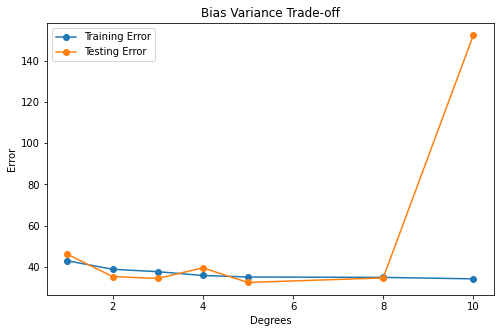

In [31]:
plt.figure(figsize=(8,5))
plt.plot(degrees,train_error,marker='o',label="Training Error")
plt.plot(degrees,test_error,marker='o',label="Testing Error")
plt.xlabel("Degrees")
plt.ylabel("Error")
plt.title("Bias Variance Trade-off")
plt.legend()
plt.show()